# Poster Result Analysis

This notebook reproduces the quantitative results reported in the NLP research poster directly from the project dataset and implementation.

Analysis cells import and call the existing project modules (the shared preprocessing pipeline, the inverted-index builder, and the retrieval code in `src/`) instead of reimplementing their logic, so every number shown here is produced by the same code path the search system uses.

## 1. Dataset Statistics

This section loads the same source documents used by the retrieval system, applies the same shared preprocessing pipeline, and builds the same inverted index.

The corpus and index statistics reported in the poster are then derived programmatically from that index and its document-length table.

In [1]:
# ---------------------------------------------------------------------------
# Path setup
# ---------------------------------------------------------------------------
import sys
from pathlib import Path


def find_project_root(start):
    '''Return the project root that contains both src/ and Dataset/.

    Walks upward from start, so the notebook works whether Jupyter was
    launched from the project root or from the notebooks/ directory.
    '''
    for candidate in (start, *start.parents):
        has_src = (candidate / 'src' / 'inverted_index.py').is_file()
        has_dataset = (candidate / 'Dataset' / 'ShortStories').is_dir()
        if has_src and has_dataset:
            return candidate
    raise FileNotFoundError(
        'Could not locate the project root (expected src/ and Dataset/) at '
        f'or above {start}'
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())

# ---------------------------------------------------------------------------
# Imports
# ---------------------------------------------------------------------------
# The project modules use flat imports ('from text_preprocessing import ...'),
# so src/ itself has to be importable.
SRC_DIR = PROJECT_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import statistics

import pandas as pd
from nltk.stem import PorterStemmer

from text_preprocessing import load_stopwords, preprocess_text
from inverted_index import (
    DOCS_DIR,
    STOPWORDS_PATH,
    build_inverted_index,
    load_documents,
)

print(f'Project root : {PROJECT_ROOT}')
print(f'Documents    : {DOCS_DIR}')
print(f'Stopwords    : {STOPWORDS_PATH}')

# ---------------------------------------------------------------------------
# Corpus loading
# ---------------------------------------------------------------------------
# Same stopword list and same stemmer the retrieval implementation uses.
stop_words = load_stopwords(STOPWORDS_PATH)
stemmer = PorterStemmer()

raw_documents = load_documents(DOCS_DIR)
doc_ids = [doc_id for doc_id, _ in raw_documents]

# ---------------------------------------------------------------------------
# Preprocessing and index construction
# ---------------------------------------------------------------------------
# Every document goes through the shared pipeline exactly as indexing does.
processed_documents = [
    (doc_id, preprocess_text(text, stop_words, stemmer))
    for doc_id, text in raw_documents
]

inverted_index, document_lengths = build_inverted_index(processed_documents)

# ---------------------------------------------------------------------------
# Statistics
# ---------------------------------------------------------------------------
documents = len(document_lengths)                   # source documents indexed
vocabulary = len(inverted_index)                    # unique processed terms
term_occurrences = sum(document_lengths.values())   # processed term occurrences
mean_length = term_occurrences / documents
median_length = statistics.median(document_lengths.values())

# ---------------------------------------------------------------------------
# Sanity checks
# ---------------------------------------------------------------------------
assert doc_ids == list(range(1, len(doc_ids) + 1)), (
    'document IDs are not 1..N with no gaps'
)
assert len(raw_documents) == len(document_lengths), (
    'loaded documents and document-length entries disagree'
)
assert vocabulary == len(inverted_index), (
    'vocabulary size does not match len(inverted_index)'
)
assert term_occurrences == sum(document_lengths.values()), (
    'term occurrences do not match the document-length table'
)

# ---------------------------------------------------------------------------
# Result table
# ---------------------------------------------------------------------------
# The Value column is pre-formatted for display. The numeric values remain
# available as documents, vocabulary, term_occurrences, mean_length and
# median_length for later analysis sections.
results = pd.DataFrame(
    {
        'Statistic': [
            'Documents',
            'Index vocabulary',
            'Indexed term occurrences',
            'Mean document length',
            'Median document length',
        ],
        'Value': [
            f'{documents:d}',
            f'{vocabulary:,d}',
            f'{term_occurrences:,d}',
            f'{mean_length:,.2f}',
            f'{median_length:,.1f}',
        ],
    }
)

results

Project root : /Users/yougeshdhomeja/Documents/NLP_Poster_Presentation
Documents    : /Users/yougeshdhomeja/Documents/NLP_Poster_Presentation/Dataset/ShortStories
Stopwords    : /Users/yougeshdhomeja/Documents/NLP_Poster_Presentation/Dataset/Stopword-List.txt


,Statistic,Value
0,Documents,50
1,Index vocabulary,"6,206"
2,Indexed term occurrences,"88,192"
3,Mean document length,"1,763.84"
4,Median document length,"1,210.5"


## 2. Representative Queries

The shared inverted index, document-length table, stopword list and stemmer built in Section 1 are reused here unchanged; nothing is rebuilt.

Four raw queries are run through the retrieval methods:

| Raw query | Illustrates |
|---|---|
| `power AND play` | Boolean filtering versus ranked retrieval |
| `passenger` | a TF-IDF / BM25 rank inversion |
| `presence` | a query on which TF-IDF and BM25 agree over the whole ranking |
| `prison OR watchman` | Boolean `OR` as a set union (Boolean-only illustration) |

Boolean applies its operator as a set operation over postings, while the two ranked methods receive the whole query string as free text and score documents by relevance. The operator therefore does **not** carry the same meaning in every method: for `power AND play`, Boolean intersects the postings of `power` and `play`, whereas the ranked methods process the whole string, drop `and` as a stopword, and score the terms `power` and `play`. `or` is **not** in the stopword list, so for `prison OR watchman` Boolean uses the two operands `prison` and `watchman`, while TF-IDF and BM25 score the three terms `prison`, `or` and `watchman`.


In [2]:

# ---------------------------------------------------------------------------
# Retrieval imports
# ---------------------------------------------------------------------------
# Section 1 already put src/ on sys.path and built inverted_index,
# document_lengths, stop_words and stemmer, so those are reused as they are.
from IPython.display import display
from search_engine import (
    parse_boolean_query,
    preprocess_boolean_terms,
    boolean_search,
    get_postings,
)
from text_preprocessing import preprocess_text
from ranking_methods.tfidf import rank_tfidf
from ranking_methods.bm25 import rank_bm25

QUERIES = [
    "power AND play",
    "passenger",
    "presence",
    "prison OR watchman",
]
TOP_K = 10
TOTAL_DOCS = len(document_lengths)   # N, the same value both ranked methods use
BOOLEAN_IDS_PER_LINE = 4             # the poster table wraps long id sets


def run_query(raw_query):
    """Run one raw query through Boolean, TF-IDF and BM25.

    Both sides are computed for every query, including the OR query, so the
    two readings of the same string can be compared directly: Boolean reads
    AND/OR as operators, while the ranked methods read the whole string as
    free text. For "prison OR watchman" that means Boolean uses
    ["prison", "watchman"], whereas the ranked methods score
    ["prison", "or", "watchman"], because "or" is not in the stopword list
    and survives preprocessing as an ordinary indexed term.

    Returns the raw computed objects without rounding or formatting, so the
    assertions below test the actual retrieval results.
    """
    # Boolean: the operator is applied across the postings of each operand.
    operator, raw_terms = parse_boolean_query(raw_query)
    boolean_terms = preprocess_boolean_terms(raw_terms, stop_words, stemmer)
    boolean_ids = boolean_search(inverted_index, raw_query, stop_words, stemmer)

    # Ranked methods: the whole query string is preprocessed as free text.
    ranked_terms = preprocess_text(raw_query, stop_words, stemmer)

    return {
        "query": raw_query,
        "operator": operator,
        "boolean_terms": boolean_terms,
        "boolean_ids": boolean_ids,
        "ranked_terms": ranked_terms,
        "tfidf_ranking": rank_tfidf(
            inverted_index, ranked_terms, TOTAL_DOCS, top_k=TOP_K
        ),
        "bm25_ranking": rank_bm25(
            inverted_index, document_lengths, ranked_terms, TOTAL_DOCS, top_k=TOP_K
        ),
    }


RESULTS = [run_query(query) for query in QUERIES]
BY_QUERY = {result["query"]: result for result in RESULTS}


def top_ids(ranking, n=3):
    """Top-n document IDs of a ranked result, in rank order."""
    return [doc_id for doc_id, _ in ranking[:n]]


def all_ids(ranking):
    """Every returned document ID, in rank order."""
    return [doc_id for doc_id, _ in ranking]


def format_boolean_set(ids):
    """The complete Boolean result as an unordered set of document IDs.

    Braces and no arrows: Boolean output carries no relevance ordering.
    """
    return "{" + ", ".join(str(doc_id) for doc_id in sorted(ids)) + "}"


def wrap_boolean_set(ids, per_line=BOOLEAN_IDS_PER_LINE):
    """The complete Boolean set, balanced over the fewest lines that hold it.

    Every Boolean row shows all of its document IDs. A long set is wrapped
    onto further lines rather than abbreviated, so the poster font never has
    to shrink to make it fit.
    """
    ordered = sorted(ids)
    if len(ordered) <= per_line:
        return format_boolean_set(ordered)
    line_count = -(-len(ordered) // per_line)           # ceil division
    per_line, extra = divmod(len(ordered), line_count)  # balanced line lengths
    lines, start = [], 0
    for line_index in range(line_count):
        size = per_line + 1 if line_index < extra else per_line
        lines.append(
            ", ".join(str(doc_id) for doc_id in ordered[start:start + size])
        )
        start += size
    lines = [line + "," for line in lines[:-1]] + lines[-1:]   # keep the commas
    lines[0] = "{" + lines[0]
    lines[-1] = lines[-1] + "}"
    return "\n".join(lines)


def format_ranked(ranking, n=3):
    """A ranked cell: top-n document IDs joined in rank order."""
    return " > ".join(f"Doc {doc_id}" for doc_id in top_ids(ranking, n))


def format_scores(ranking, n=3):
    """Rounded for display only; the ranking objects keep full precision."""
    return ", ".join(f"{score:.4f}" for _, score in ranking[:n])


# ---------------------------------------------------------------------------
# Assertions: every expected value is checked against the computed results
# ---------------------------------------------------------------------------
and_play = BY_QUERY["power AND play"]
assert and_play["operator"] == "AND"
assert and_play["boolean_terms"] == ["power", "play"]
assert and_play["ranked_terms"] == ["power", "play"]
assert and_play["boolean_ids"] == [2, 9, 10, 47]
assert len(and_play["boolean_ids"]) == 4
assert top_ids(and_play["tfidf_ranking"]) == [9, 30, 47]
assert top_ids(and_play["bm25_ranking"]) == [9, 47, 30]

passenger = BY_QUERY["passenger"]
assert passenger["operator"] is None            # single term: no operator
assert passenger["boolean_terms"] == ["passeng"]
assert passenger["ranked_terms"] == ["passeng"]
assert passenger["boolean_terms"] == passenger["ranked_terms"]
assert passenger["boolean_ids"] == [2, 5, 19, 41, 43]
assert len(passenger["boolean_ids"]) == 5
assert top_ids(passenger["tfidf_ranking"]) == [19, 41, 43]
assert top_ids(passenger["bm25_ranking"]) == [41, 19, 43]

presence = BY_QUERY["presence"]
assert presence["operator"] is None             # single term: no operator
assert presence["boolean_terms"] == ["presenc"]
assert presence["ranked_terms"] == ["presenc"]
assert presence["boolean_terms"] == presence["ranked_terms"]
assert presence["boolean_ids"] == [1, 2, 22, 23, 27, 31, 35, 37, 47, 48]
assert len(presence["boolean_ids"]) == 10
assert top_ids(presence["tfidf_ranking"]) == [48, 37, 47]
assert top_ids(presence["bm25_ranking"]) == [48, 37, 47]
# The agreement is not limited to the top of the list: both methods return
# the same ten documents in the same order.
assert all_ids(presence["tfidf_ranking"]) == [48, 37, 47, 27, 35, 31, 22, 2, 23, 1]
assert all_ids(presence["bm25_ranking"]) == [48, 37, 47, 27, 35, 31, 22, 2, 23, 1]
assert all_ids(presence["tfidf_ranking"]) == all_ids(presence["bm25_ranking"])

or_pair = BY_QUERY["prison OR watchman"]
# Boolean side: OR is an operator applied across two postings.
assert or_pair["operator"] == "OR"
assert or_pair["boolean_terms"] == ["prison", "watchman"]
prison_postings = sorted(get_postings(inverted_index, "prison"))
watchman_postings = sorted(get_postings(inverted_index, "watchman"))
assert prison_postings == [1, 2, 8, 10, 34, 35]
assert watchman_postings == [25, 27, 33, 38]
or_intersection = sorted(set(prison_postings) & set(watchman_postings))
or_union = sorted(set(prison_postings) | set(watchman_postings))
assert or_intersection == []                    # the two postings are disjoint
assert or_union == [1, 2, 8, 10, 25, 27, 33, 34, 35, 38]
assert or_pair["boolean_ids"] == or_union
assert len(or_pair["boolean_ids"]) == 10
# Ranked side: the same string read as free text, where "or" is not an
# operator at all but an ordinary indexed term.
assert or_pair["ranked_terms"] == ["prison", "or", "watchman"]
assert or_pair["ranked_terms"] != or_pair["boolean_terms"]
assert len(or_pair["ranked_terms"]) == 3
assert "or" not in stop_words
assert "or" in inverted_index
assert or_pair["tfidf_ranking"]                   # TF-IDF returned a ranking
assert or_pair["bm25_ranking"]                    # BM25 returned a ranking
assert len(or_pair["tfidf_ranking"]) >= 3
assert len(or_pair["bm25_ranking"]) >= 3

# Every query - the OR query included - carries real ranked results, and no
# ranked cell is ever left blank or dashed.
for result in RESULTS:
    assert result["tfidf_ranking"]
    assert result["bm25_ranking"]
    assert len(result["tfidf_ranking"]) >= 3
    assert len(result["bm25_ranking"]) >= 3
    assert "—" not in format_ranked(result["tfidf_ranking"])
    assert "—" not in format_ranked(result["bm25_ranking"])
    assert "—" not in format_scores(result["tfidf_ranking"])
    assert "—" not in format_scores(result["bm25_ranking"])
    assert format_ranked(result["tfidf_ranking"]).count(" > ") == 2
    assert format_ranked(result["bm25_ranking"]).count(" > ") == 2

# Display rule: every Boolean row shows its COMPLETE document-ID set, wrapped
# onto further lines when it is long - never replaced by a match count.
assert wrap_boolean_set(and_play["boolean_ids"]) == "{2, 9, 10, 47}"
assert wrap_boolean_set(passenger["boolean_ids"]) == "{2, 5, 19,\n41, 43}"
assert wrap_boolean_set(presence["boolean_ids"]) == (
    "{1, 2, 22, 23,\n27, 31, 35,\n37, 47, 48}"
)
assert wrap_boolean_set(or_pair["boolean_ids"]) == (
    "{1, 2, 8, 10,\n25, 27, 33,\n34, 35, 38}"
)
for result in RESULTS:
    shown = [
        int(part)
        for part in (
            wrap_boolean_set(result["boolean_ids"])
            .replace("{", "").replace("}", "").replace("\n", " ")
            .replace(",", " ").split()
        )
    ]
    assert shown == sorted(result["boolean_ids"])   # every id is printed
    assert len(shown) == len(result["boolean_ids"])

ASSERTION_COUNT = 59  # assert statements here; the 10 inside the loops below
#                       run once per query, so 89 checks execute in total
print(
    f"All {ASSERTION_COUNT} assertion statements passed for {len(RESULTS)} queries ("
    + ", ".join(repr(r["query"]) for r in RESULTS)
    + ")"
)

# ---------------------------------------------------------------------------
# Verification table (scores rounded to 4 decimals for display only)
# ---------------------------------------------------------------------------
verification = pd.DataFrame(
    [
        {
            "Query": result["query"],
            "Boolean Operator": result["operator"] or "(single term)",
            "Boolean Terms": ", ".join(str(t) for t in result["boolean_terms"]),
            "Ranked Terms": ", ".join(result["ranked_terms"]),
            "Boolean Doc IDs": format_boolean_set(result["boolean_ids"]),
            "Boolean Count": len(result["boolean_ids"]),
            "TF-IDF Top-3 Doc IDs": format_ranked(result["tfidf_ranking"]),
            "TF-IDF Top-3 Scores": format_scores(result["tfidf_ranking"]),
            "BM25 Top-3 Doc IDs": format_ranked(result["bm25_ranking"]),
            "BM25 Top-3 Scores": format_scores(result["bm25_ranking"]),
        }
        for result in RESULTS
    ]
)

display(verification)


All 59 assertion statements passed for 4 queries ('power AND play', 'passenger', 'presence', 'prison OR watchman')


,Query,Boolean Operator,Boolean Terms,Ranked Terms,Boolean Doc IDs,Boolean Count,TF-IDF Top-3 Doc IDs,TF-IDF Top-3 Scores,BM25 Top-3 Doc IDs,BM25 Top-3 Scores
0,power AND play,AND,"power, play","power, play","{2, 9, 10, 47}",4,Doc 9 > Doc 30 > Doc 47,"0.0505, 0.0486, 0.0355",Doc 9 > Doc 47 > Doc 30,"4.5829, 3.5551, 2.9187"
1,passenger,(single term),passeng,passeng,"{2, 5, 19, 41, 43}",5,Doc 19 > Doc 41 > Doc 43,"0.2263, 0.1750, 0.0416",Doc 41 > Doc 19 > Doc 43,"4.9529, 4.9113, 3.5859"
2,presence,(single term),presenc,presenc,"{1, 2, 22, 23, 27, 31, 35, 37, 47, 48}",10,Doc 48 > Doc 37 > Doc 47,"0.0860, 0.0330, 0.0271",Doc 48 > Doc 37 > Doc 47,"3.0680, 2.5416, 2.0873"
3,prison OR watchman,OR,"prison, watchman","prison, or, watchman","{1, 2, 8, 10, 25, 27, 33, 34, 35, 38}",10,Doc 33 > Doc 34 > Doc 10,"0.4364, 0.1710, 0.0742",Doc 33 > Doc 34 > Doc 10,"5.8894, 4.7959, 4.4154"


,Query,Boolean Doc IDs,TF-IDF Top-3 Doc IDs,BM25 Top-3 Doc IDs
0,power AND play,"{2, 9, 10, 47}",Doc 9 > Doc 30 > Doc 47,Doc 9 > Doc 47 > Doc 30
1,passenger,"{2, 5, 19,\n41, 43}",Doc 19 > Doc 41 > Doc 43,Doc 41 > Doc 19 > Doc 43
2,presence,"{1, 2, 22, 23,\n27, 31, 35,\n37, 47, 48}",Doc 48 > Doc 37 > Doc 47,Doc 48 > Doc 37 > Doc 47
3,prison OR watchman,"{1, 2, 8, 10,\n25, 27, 33,\n34, 35, 38}",Doc 33 > Doc 34 > Doc 10,Doc 33 > Doc 34 > Doc 10


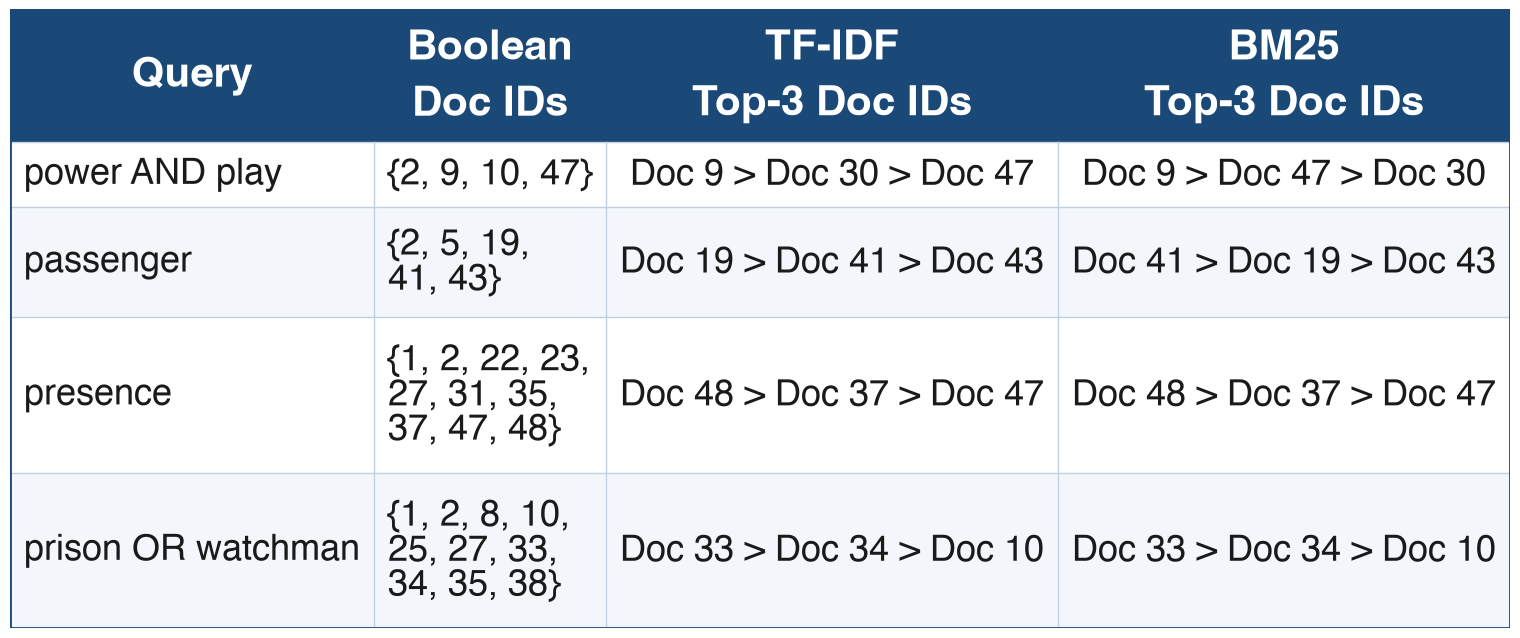

Output path        : /Users/yougeshdhomeja/Documents/NLP_Poster_Presentation/images/representative_queries_table.png
Pixel width        : 9120 px
Pixel height       : 3832 px
File size          : 790,031 bytes
Format             : PNG
Header font size   : 30.0 pt
Body font size     : 26.0 pt
Figure canvas size : 15.00 x 6.19 in
DPI (metadata)     : 600 x 600
Physical size      : 15.20 x 6.39 in
Body text at 18 cm column:  12.3 pt   (table height 2.92 in)
Body text at 28 cm column:  19.1 pt   (table height 4.55 in)
Body text at 36 cm column:  24.6 pt   (table height 5.85 in)
Body text at 40 cm column:  27.3 pt   (table height 6.50 in)
Body text at 59 cm column:  40.3 pt   (table height 9.58 in)


In [3]:
# ---------------------------------------------------------------------------
# Poster summary table
# ---------------------------------------------------------------------------
# Every cell is built from the computed result objects above; no retrieval
# value is typed in by hand.
summary = pd.DataFrame(
    [
        {
            "Query": result["query"],
            "Boolean Doc IDs": wrap_boolean_set(result["boolean_ids"]),
            "TF-IDF Top-3 Doc IDs": format_ranked(result["tfidf_ranking"]),
            "BM25 Top-3 Doc IDs": format_ranked(result["bm25_ranking"]),
        }
        for result in RESULTS
    ]
)

display(summary)

# ---------------------------------------------------------------------------
# Poster figure
# ---------------------------------------------------------------------------
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

IMAGE_DIR = PROJECT_ROOT / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_PATH = IMAGE_DIR / "representative_queries_table.png"

POSTER_BLUE = (26 / 255, 73 / 255, 120 / 255)   # poster header blue
ROW_TINT = "#F3F7FB"                            # subtle alternating row
GRID_COLOUR = "#BFD0E0"
TEXT_COLOUR = "#1A1A1A"

HEADER_FONT = 30.0      # large enough to survive being scaled into a column
BODY_FONT = 26.0
PAD_X = 14.0            # horizontal cell padding, layout pixels (fixed)
PAD_Y = 10.0            # vertical cell padding, layout pixels (fixed)
LAYOUT_DPI = 100        # layout resolution only; the export is at 600 dpi

plt.rcParams["font.family"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["figure.facecolor"] = "white"

# Header labels; the ranked columns wrap onto two lines so they stay narrow
# and the width can go to the document-ID strings underneath. The Boolean
# column's long id sets are wrapped inside the cell, not abbreviated.
COLUMNS = [
    ("Query",),
    ("Boolean", "Doc IDs"),
    ("TF-IDF", "Top-3 Doc IDs"),
    ("BM25", "Top-3 Doc IDs"),
]


def measure(label, fontsize, weight="normal"):
    """Width of a label in layout pixels, using matplotlib's own metrics.

    For a multi-line label this is the width of its widest line, which is
    what the column has to hold.
    """
    probe = plt.figure(figsize=(1, 1), dpi=LAYOUT_DPI)
    probe.canvas.draw()
    renderer = probe.canvas.get_renderer()
    text = probe.text(0, 0, label, fontsize=fontsize, fontweight=weight)
    width = text.get_window_extent(renderer=renderer).width
    plt.close(probe)
    return width


rows = summary.values.tolist()
lines_in_row = [max(str(cell).count("\n") + 1 for cell in row) for row in rows]

# Column widths are driven by the widest string each column must hold, so no
# cell can clip. The Query column stays narrow and the document-ID columns
# take the space.
column_widths = []
for index, lines in enumerate(COLUMNS):
    widths = [measure(line, HEADER_FONT, "bold") for line in lines]
    widths += [measure(str(row[index]), BODY_FONT) for row in rows]
    column_widths.append(max(widths) + 2 * PAD_X)

header_line = HEADER_FONT * LAYOUT_DPI / 72.0 * 1.35
body_line = BODY_FONT * LAYOUT_DPI / 72.0 * 1.25
header_height = max(len(lines) for lines in COLUMNS) * header_line + 2 * PAD_Y
# Rows are as tall as their tallest cell, so a wrapped Boolean set is never
# squeezed and the font size never has to be reduced.
row_heights = [lines * body_line + 2 * PAD_Y for lines in lines_in_row]
total_width = sum(column_widths)
total_height = header_height + sum(row_heights)

figure = plt.figure(
    figsize=(total_width / LAYOUT_DPI, total_height / LAYOUT_DPI),
    dpi=LAYOUT_DPI,
    facecolor="white",
)
axes = figure.add_axes([0, 0, 1, 1])
axes.set_xlim(0, total_width)
axes.set_ylim(total_height, 0)   # y grows downwards, so rows read top-down
axes.set_axis_off()

# Solid header band
axes.add_patch(
    Rectangle((0, 0), total_width, header_height,
              facecolor=POSTER_BLUE, edgecolor="none", zorder=1)
)

# Body rows: white, with a very subtle tint on alternate rows
row_top = header_height
for row_index, height in enumerate(row_heights):
    if row_index % 2:
        axes.add_patch(
            Rectangle((0, row_top), total_width, height,
                      facecolor=ROW_TINT, edgecolor="none", zorder=1)
        )
    row_top += height

# Thin horizontal rules between body rows
row_top = header_height
for height in row_heights:
    axes.plot([0, total_width], [row_top, row_top],
              color=GRID_COLOUR, linewidth=1.0, zorder=3)
    row_top += height

# Thin vertical rules between columns (body only, so the header stays solid)
x = 0.0
for column_index, width in enumerate(column_widths):
    if column_index:
        axes.plot([x, x], [header_height, total_height],
                  color=GRID_COLOUR, linewidth=1.0, zorder=3)
    x += width

# Unobtrusive outer frame
axes.add_patch(
    Rectangle((0, 0), total_width, total_height, fill=False,
              edgecolor=POSTER_BLUE, linewidth=2.0, zorder=4)
)

# Header labels, each line centred in its cell
x = 0.0
for lines, width in zip(COLUMNS, column_widths):
    block_height = len(lines) * header_line
    first_baseline = (header_height - block_height) / 2 + header_line / 2
    for line_index, line in enumerate(lines):
        axes.text(
            x + width / 2,
            first_baseline + line_index * header_line,
            line,
            ha="center", va="center", color="white",
            fontsize=HEADER_FONT, fontweight="bold", zorder=5,
        )
    x += width

# Body cells: Query and Boolean left-aligned, ranked columns centred
row_top = header_height
for row, height in zip(rows, row_heights):
    x = 0.0
    for column_index, value in enumerate(row):
        if column_index < 2:
            text_x, text_ha = x + PAD_X, "left"
        else:
            text_x, text_ha = x + column_widths[column_index] / 2, "center"
        axes.text(
            text_x, row_top + height / 2, str(value),
            ha=text_ha, va="center", color=TEXT_COLOUR,
            fontsize=BODY_FONT, zorder=5,
        )
        x += column_widths[column_index]
    row_top += height

figure.savefig(FIGURE_PATH, dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

# ---------------------------------------------------------------------------
# Saved image properties
# ---------------------------------------------------------------------------
with Image.open(FIGURE_PATH) as saved_image:
    pixel_width, pixel_height = saved_image.size
    saved_format = saved_image.format
    saved_dpi = saved_image.info.get("dpi")

file_size = os.path.getsize(FIGURE_PATH)
print(f"Output path        : {FIGURE_PATH}")
print(f"Pixel width        : {pixel_width} px")
print(f"Pixel height       : {pixel_height} px")
print(f"File size          : {file_size:,} bytes")
print(f"Format             : {saved_format}")
print(f"Header font size   : {HEADER_FONT} pt")
print(f"Body font size     : {BODY_FONT} pt")
print(f"Figure canvas size : {total_width / LAYOUT_DPI:.2f} x "
      f"{total_height / LAYOUT_DPI:.2f} in")
if saved_dpi:
    print(f"DPI (metadata)     : {saved_dpi[0]:.0f} x {saved_dpi[1]:.0f}")
    print(f"Physical size      : {pixel_width / saved_dpi[0]:.2f} x "
          f"{pixel_height / saved_dpi[1]:.2f} in")
else:
    print("DPI (metadata)     : not recorded in the PNG")

# Rendered body-text size if the figure is placed with width=\linewidth
# (the figure is scaled by column_width / figure_width).
figure_width_in = total_width / LAYOUT_DPI
for label, column_cm in (("18 cm", 18.0), ("28 cm", 28.0), ("36 cm", 36.0),
                         ("40 cm", 40.0), ("59 cm", 59.0)):
    column_in = column_cm / 2.54
    print(f"Body text at {label:>5s} column: "
          f"{BODY_FONT * column_in / figure_width_in:5.1f} pt   "
          f"(table height {total_height / LAYOUT_DPI * column_in / figure_width_in:.2f} in)")


For Boolean retrieval, `AND` / `OR` are interpreted as operators. Ranked methods preprocess the full raw query as free text. Therefore, for `prison OR watchman`, Boolean uses `prison` and `watchman`, while TF-IDF and BM25 score `prison`, `or`, and `watchman`. Boolean results are unranked, while TF-IDF and BM25 document IDs are shown in rank order.


## 3. Ranking Inversion Example

The index, document-length table, stopword list and stemmer built in Section 1 are reused unchanged; nothing is rebuilt. This section recomputes, for the raw query `passenger`, the complete TF-IDF and BM25 rankings and the document statistics behind the inversion between the two top-ranked documents.


In [4]:
# ---------------------------------------------------------------------------
# Section 3 setup
# ---------------------------------------------------------------------------
# Section 1 put src/ on sys.path and built inverted_index, document_lengths,
# stop_words and stemmer; Section 2 defined TOP_K and TOTAL_DOCS along with the
# top_ids / all_ids helpers. All of them are reused here unchanged.
import math

import pandas as pd
from IPython.display import display

from text_preprocessing import preprocess_text
from ranking_methods.tfidf import (
    calculate_document_norms,
    calculate_idf_values,
    rank_tfidf,
)
from ranking_methods.bm25 import (
    DEFAULT_B,
    DEFAULT_K1,
    calculate_average_document_length,
    calculate_bm25_idf_values,
    calculate_bm25_term_score,
    rank_bm25,
)

RQ2_QUERY = "passenger"
RQ2_N = len(document_lengths)   # N, the same total both ranked methods use
RQ2_DOCS = [19, 41, 43]         # the inversion pair plus the next document
SCORE_TOLERANCE = 5e-5          # the table rounds displayed values to 4 decimals

assert RQ2_N == TOTAL_DOCS, "Section 3 must use the same N as Section 2"

# ---------------------------------------------------------------------------
# Query processing and retrieval (real project functions, real corpus)
# ---------------------------------------------------------------------------
rq2_terms = preprocess_text(RQ2_QUERY, stop_words, stemmer)
RQ2_TERM = rq2_terms[0]
rq2_candidates = sorted(inverted_index[RQ2_TERM])

rq2_tfidf = rank_tfidf(inverted_index, rq2_terms, RQ2_N, top_k=TOP_K)
rq2_bm25 = rank_bm25(inverted_index, document_lengths, rq2_terms, RQ2_N, top_k=TOP_K)
rq2_tfidf_scores = dict(rq2_tfidf)
rq2_bm25_scores = dict(rq2_bm25)

# ---------------------------------------------------------------------------
# Document statistics behind the scores
# ---------------------------------------------------------------------------
# The IDF tables, the document norms and the average document length are the
# same quantities the two ranking modules build internally; recomputing them
# here only exposes the intermediate values, and every score is still taken
# from the rank_* functions above.
rq2_tfidf_idf = calculate_idf_values(inverted_index, RQ2_N)
rq2_doc_norms = calculate_document_norms(inverted_index, rq2_tfidf_idf)
rq2_bm25_idf = calculate_bm25_idf_values(inverted_index, RQ2_N)
rq2_avgdl = calculate_average_document_length(document_lengths)


def rq2_length_factor(doc_id):
    """BM25 length normalisation 1 - b + b * |d| / avgdl (bm25.py:120)."""
    return 1.0 - DEFAULT_B + DEFAULT_B * (document_lengths[doc_id] / rq2_avgdl)


rq2_rows = []
for doc_id in RQ2_DOCS:
    rq2_rows.append(
        {
            "Document": f"Doc {doc_id}",
            "TF(passeng)": inverted_index[RQ2_TERM][doc_id],
            "Length": document_lengths[doc_id],
            "TF-IDF norm": rq2_doc_norms[doc_id],
            "TF-IDF score": rq2_tfidf_scores[doc_id],
            "BM25 length factor": rq2_length_factor(doc_id),
            # The term score comes from the BM25 module itself.
            "BM25 score": calculate_bm25_term_score(
                RQ2_TERM, doc_id, inverted_index, rq2_bm25_idf,
                document_lengths, rq2_avgdl, DEFAULT_K1, DEFAULT_B,
            ),
        }
    )

RQ2_BY_DOC = {doc_id: row for doc_id, row in zip(RQ2_DOCS, rq2_rows)}

# ---------------------------------------------------------------------------
# Assertions: the computed values are checked against the verified values
# ---------------------------------------------------------------------------
assert rq2_terms == ["passeng"], "passenger must preprocess to passeng"
assert len(rq2_terms) == 1, "the example is a single-term query"
assert rq2_candidates == [2, 5, 19, 41, 43]
assert len(rq2_candidates) == 5

# Complete rankings, not just the top of the list
assert all_ids(rq2_tfidf) == [19, 41, 43, 5, 2]
assert all_ids(rq2_bm25) == [41, 19, 43, 5, 2]
assert len(rq2_tfidf) == len(rq2_candidates)
assert len(rq2_bm25) == len(rq2_candidates)

# The inversion is in the top two ranks and only there
assert top_ids(rq2_tfidf, 2) == [19, 41]
assert top_ids(rq2_bm25, 2) == [41, 19]
assert top_ids(rq2_tfidf, 2) != top_ids(rq2_bm25, 2)
assert top_ids(rq2_tfidf)[0] == 19 and top_ids(rq2_bm25)[0] == 41

# Single-term query: the IDF of the query term is one constant for every
# document, and the cosine reduces to TF * IDF / ||d|| (tfidf.py:169).
assert math.isclose(
    rq2_tfidf_idf[RQ2_TERM] * RQ2_BY_DOC[19]["TF(passeng)"]
    / RQ2_BY_DOC[19]["TF-IDF norm"],
    rq2_tfidf_scores[19], abs_tol=1e-12,
)

# Verified values for the three documents
RQ2_EXPECTED = {
    19: {"tf": 9, "length": 1298, "norm": 91.56,
         "tfidf": 0.2263, "length_factor": 0.8019, "bm25": 4.9113},
    41: {"tf": 8, "length": 969, "norm": 105.26,
         "tfidf": 0.1750, "length_factor": 0.6620, "bm25": 4.9529},
    43: {"tf": 2, "length": 1145, "norm": 110.68,
         "tfidf": 0.0416, "length_factor": 0.7369, "bm25": 3.5859},
}
for doc_id, expected in RQ2_EXPECTED.items():
    row = RQ2_BY_DOC[doc_id]
    assert row["TF(passeng)"] == expected["tf"]
    assert row["Length"] == expected["length"]
    assert math.isclose(row["TF-IDF norm"], expected["norm"], abs_tol=0.01)
    assert math.isclose(row["TF-IDF score"], expected["tfidf"],
                        abs_tol=SCORE_TOLERANCE)
    assert math.isclose(row["BM25 length factor"], expected["length_factor"],
                        abs_tol=SCORE_TOLERANCE)
    assert math.isclose(row["BM25 score"], expected["bm25"],
                        abs_tol=SCORE_TOLERANCE)
    # Every score in the table is the score the ranker actually returned.
    assert row["TF-IDF score"] == rq2_tfidf_scores[doc_id]
    assert row["BM25 score"] == rq2_bm25_scores[doc_id]

# The two documents that swap places differ in opposite directions
assert RQ2_BY_DOC[19]["TF(passeng)"] > RQ2_BY_DOC[41]["TF(passeng)"]
assert RQ2_BY_DOC[19]["TF-IDF norm"] < RQ2_BY_DOC[41]["TF-IDF norm"]
assert RQ2_BY_DOC[19]["Length"] > RQ2_BY_DOC[41]["Length"]
assert RQ2_BY_DOC[19]["BM25 length factor"] > RQ2_BY_DOC[41]["BM25 length factor"]
assert RQ2_BY_DOC[19]["TF-IDF score"] > RQ2_BY_DOC[41]["TF-IDF score"]
assert RQ2_BY_DOC[19]["BM25 score"] < RQ2_BY_DOC[41]["BM25 score"]

RQ2_ASSERTION_COUNT = 28  # assert statements in this cell; the 8 inside
#                             the loop run once per document, so 44 checks
#                             execute in total
print(
    f"All {RQ2_ASSERTION_COUNT} Section 3 assertion statements passed for "
    f"{RQ2_QUERY!r}"
)

# ---------------------------------------------------------------------------
# Complete rankings (scores rounded to 4 decimals for display only)
# ---------------------------------------------------------------------------
rq2_rankings = pd.DataFrame(
    {
        "Rank": range(1, len(rq2_tfidf) + 1),
        "TF-IDF Doc ID": all_ids(rq2_tfidf),
        "TF-IDF Score": [round(score, 4) for _, score in rq2_tfidf],
        "BM25 Doc ID": all_ids(rq2_bm25),
        "BM25 Score": [round(score, 4) for _, score in rq2_bm25],
    }
)
display(rq2_rankings)

# ---------------------------------------------------------------------------
# Compact explanation table (rounded for display; the figure uses these rows)
# ---------------------------------------------------------------------------
rq2_table = pd.DataFrame(
    [
        {
            "Document": row["Document"],
            "TF(passeng)": row["TF(passeng)"],
            "Length": row["Length"],
            "TF-IDF norm": f"{row['TF-IDF norm']:.2f}",
            "TF-IDF score": f"{row['TF-IDF score']:.4f}",
            "BM25 length factor": f"{row['BM25 length factor']:.4f}",
            "BM25 score": f"{row['BM25 score']:.4f}",
        }
        for row in rq2_rows
    ],
    columns=[
        "Document",
        "TF(passeng)",
        "Length",
        "TF-IDF norm",
        "TF-IDF score",
        "BM25 length factor",
        "BM25 score",
    ],
)
display(rq2_table)


All 28 Section 3 assertion statements passed for 'passenger'


,Rank,TF-IDF Doc ID,TF-IDF Score,BM25 Doc ID,BM25 Score
0,1,19,0.2263,41,4.9529
1,2,41,0.1750,19,4.9113
2,3,43,0.0416,43,3.5859
3,4,5,0.0258,5,2.6936
4,5,2,0.0055,2,0.9185


,Document,TF(passeng),Length,TF-IDF norm,TF-IDF score,BM25 length factor,BM25 score
0,Doc 19,9,1298,91.56,0.2263,0.8019,4.9113
1,Doc 41,8,969,105.26,0.1750,0.6620,4.9529
2,Doc 43,2,1145,110.68,0.0416,0.7369,3.5859


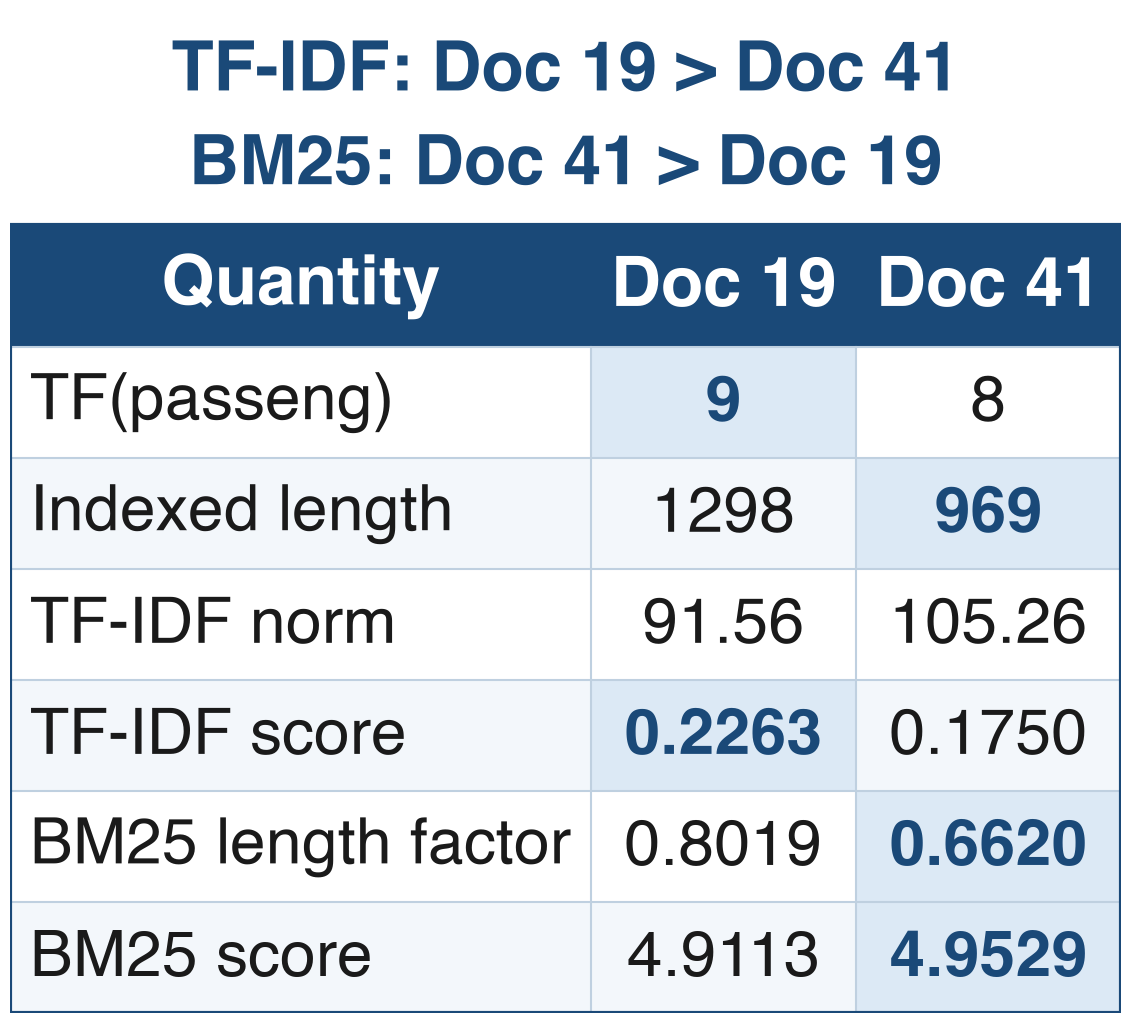

Output path        : /Users/yougeshdhomeja/Documents/NLP_Poster_Presentation/images/passenger_rank_inversion.png
Pixel width        : 6786 px
Pixel height       : 6141 px
Intrinsic width    : 11.31 in (28.7 cm)
File size          : 1,038,808 bytes
Format             : PNG
Headline font size : 50.0 pt
Header font size   : 50.0 pt (bold, white)
Body font size     : 46.0 pt
DPI (metadata)     : 600 x 600
Ink margin         : 60 px on the tightest edge (0 px would mean clipping)
Rows shown         : ['TF(passeng)', 'Indexed length', 'TF-IDF norm', 'TF-IDF score', 'BM25 length factor', 'BM25 score']
Documents shown    : ['Doc 19', 'Doc 41'] (Doc 43 stays in the computation data)
Emphasised cells   : TF(passeng) -> Doc 19; Indexed length -> Doc 41; TF-IDF score -> Doc 19; BM25 length factor -> Doc 41; BM25 score -> Doc 41
Body text at  18 cm column:  28.8 pt   (table height 6.41 in)
Body text at  20 cm column:  32.0 pt   (table height 7.13 in)
Body text at  24 cm column:  38.4 pt   (table he

In [5]:
# ---------------------------------------------------------------------------
# Poster figure: passenger rank inversion (transposed comparison)
# ---------------------------------------------------------------------------
# Every string and number below is taken from the computed objects above: the
# headline from the rankings, the row labels from rq2_table, and the emphasis
# from the values themselves. Nothing is typed in by hand.
#
# Layout note: the figure is placed on the poster at the width of the Results
# column, so the size the reader sees is
#   effective_pt = FONT * column_width / figure_width
# and the figure width grows with the font size. What sets the ceiling is the
# table's width in em, so the transposed shape (three columns of short values
# instead of seven) is what makes poster-scale type possible here.
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from PIL import Image

IMAGE_DIR = PROJECT_ROOT / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_PATH = IMAGE_DIR / "passenger_rank_inversion.png"

POSTER_BLUE = (26 / 255, 73 / 255, 120 / 255)   # same poster header blue
ROW_TINT = "#F3F7FB"                            # subtle alternating row
EMPHASIS_FILL = "#DCE9F5"                       # one tint, used sparingly
GRID_COLOUR = "#BFD0E0"
TEXT_COLOUR = "#1A1A1A"

TITLE_FONT = 50.0
HEADER_FONT = 50.0
BODY_FONT = 46.0
PAD_X = 20.0            # horizontal cell padding, layout pixels (fixed)
PAD_Y = 14.0            # vertical cell padding, layout pixels (fixed)
LAYOUT_DPI = 100        # layout resolution only; the export is at 600 dpi

plt.rcParams["font.family"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["figure.facecolor"] = "white"

# ---------------------------------------------------------------------------
# Rows shown on the poster
# ---------------------------------------------------------------------------
# Doc 43 stays in the computation and verification above; the poster figure
# shows only the two documents that actually swap places.
RQ2_FIGURE_DOCS = [19, 41]
assert 43 in RQ2_DOCS, "Doc 43 must stay in the computation data"
assert RQ2_FIGURE_DOCS == sorted(RQ2_FIGURE_DOCS)
assert len(RQ2_FIGURE_DOCS) == 2

DOC_LABELS = {doc_id: f"Doc {doc_id}" for doc_id in RQ2_FIGURE_DOCS}
COMPUTED = rq2_table.set_index("Document")
assert set(DOC_LABELS.values()) <= set(COMPUTED.index)

# (row label, the computed column it is read from)
QUANTITIES = [
    ("TF(passeng)", "TF(passeng)"),
    ("Indexed length", "Length"),
    ("TF-IDF norm", "TF-IDF norm"),
    ("TF-IDF score", "TF-IDF score"),
    ("BM25 length factor", "BM25 length factor"),
    ("BM25 score", "BM25 score"),
]

table_rows = [
    [label] + [str(COMPUTED.loc[DOC_LABELS[doc_id], column])
               for doc_id in RQ2_FIGURE_DOCS]
    for label, column in QUANTITIES
]

# Every displayed string is the rounded form of the full-precision computed
# value, so the figure cannot drift from Section 3.
DECIMALS = {"TF(passeng)": 0, "Length": 0, "TF-IDF norm": 2,
            "TF-IDF score": 4, "BM25 length factor": 4, "BM25 score": 4}
for (label, column), row in zip(QUANTITIES, table_rows):
    for doc_id, shown in zip(RQ2_FIGURE_DOCS, row[1:]):
        assert float(shown) == round(RQ2_BY_DOC[doc_id][column],
                                     DECIMALS[column]), (label, doc_id, shown)

# ---------------------------------------------------------------------------
# Headline and emphasis, both derived from the computed rankings
# ---------------------------------------------------------------------------
def ranked_pair(ranking):
    """The top-two document IDs in rank order, e.g. 'Doc 19 > Doc 41'."""
    return " > ".join(f"Doc {doc_id}" for doc_id in top_ids(ranking, 2))


TITLE_LINES = [
    "TF-IDF: " + ranked_pair(rq2_tfidf),
    "BM25: " + ranked_pair(rq2_bm25),
]

tfidf_winner = top_ids(rq2_tfidf, 1)[0]      # -> 19
bm25_winner = top_ids(rq2_bm25, 1)[0]        # -> 41
higher_tf = max(RQ2_FIGURE_DOCS, key=lambda d: RQ2_BY_DOC[d]["TF(passeng)"])
shorter = min(RQ2_FIGURE_DOCS, key=lambda d: RQ2_BY_DOC[d]["Length"])
smaller_factor = min(RQ2_FIGURE_DOCS,
                     key=lambda d: RQ2_BY_DOC[d]["BM25 length factor"])

assert tfidf_winner in RQ2_FIGURE_DOCS and bm25_winner in RQ2_FIGURE_DOCS
assert tfidf_winner != bm25_winner, "the two methods must disagree here"
# the headline leads with the method's top-ranked document
assert TITLE_LINES[0] == f"TF-IDF: Doc {tfidf_winner} > Doc {bm25_winner}"
assert TITLE_LINES[1] == f"BM25: Doc {bm25_winner} > Doc {tfidf_winner}"

# The only emphasised cells: the two scores whose order swaps, plus the three
# measurements that explain it.
EMPHASIS = {
    "TF(passeng)": {higher_tf},
    "Indexed length": {shorter},
    "TF-IDF norm": set(),
    "TF-IDF score": {tfidf_winner},
    "BM25 length factor": {smaller_factor},
    "BM25 score": {bm25_winner},
}

# ---------------------------------------------------------------------------
# Geometry
# ---------------------------------------------------------------------------
def measure(label, fontsize, weight="normal"):
    """Width of a label in layout pixels, using matplotlib's own metrics."""
    probe = plt.figure(figsize=(1, 1), dpi=LAYOUT_DPI)
    probe.canvas.draw()
    renderer = probe.canvas.get_renderer()
    text = probe.text(0, 0, label, fontsize=fontsize, fontweight=weight)
    width = text.get_window_extent(renderer=renderer).width
    plt.close(probe)
    return width


header_labels = ["Quantity"] + [DOC_LABELS[d] for d in RQ2_FIGURE_DOCS]

column_widths = []
for index in range(len(header_labels)):
    widths = [measure(header_labels[index], HEADER_FONT, "bold")]
    widths += [measure(str(row[index]), BODY_FONT) for row in table_rows]
    column_widths.append(max(widths) + 2 * PAD_X)

header_line = HEADER_FONT * LAYOUT_DPI / 72.0 * 1.35
body_line = BODY_FONT * LAYOUT_DPI / 72.0 * 1.3
title_line = TITLE_FONT * LAYOUT_DPI / 72.0 * 1.35

header_height = header_line + 2 * PAD_Y
row_height = body_line + 2 * PAD_Y          # generous, single-line rows

table_width = sum(column_widths)
table_height = header_height + len(table_rows) * row_height
title_height = len(TITLE_LINES) * title_line + 2 * PAD_Y
total_width = max(table_width, max(measure(line, TITLE_FONT, "bold")
                                   for line in TITLE_LINES) + 2 * PAD_X)
total_height = title_height + table_height
table_x = (total_width - table_width) / 2   # the table block, centred

figure = plt.figure(
    figsize=(total_width / LAYOUT_DPI, total_height / LAYOUT_DPI),
    dpi=LAYOUT_DPI,
    facecolor="white",
)
axes = figure.add_axes([0, 0, 1, 1])
axes.set_xlim(0, total_width)
axes.set_ylim(total_height, 0)   # y grows downwards, so rows read top-down
axes.set_axis_off()

# Headline: the two orderings, centred above the table
for index, line in enumerate(TITLE_LINES):
    axes.text(
        total_width / 2,
        PAD_Y + title_line * (index + 0.5),
        line,
        ha="center", va="center", color=POSTER_BLUE,
        fontsize=TITLE_FONT, fontweight="bold", zorder=5,
    )

# Solid header band
axes.add_patch(
    Rectangle((table_x, title_height), table_width, header_height,
              facecolor=POSTER_BLUE, edgecolor="none", zorder=1)
)

# Body rows: white with a very subtle tint on alternate rows
row_top = title_height + header_height
for row_index, _ in enumerate(table_rows):
    if row_index % 2:
        axes.add_patch(
            Rectangle((table_x, row_top), table_width, row_height,
                      facecolor=ROW_TINT, edgecolor="none", zorder=1)
        )
    row_top += row_height

# Emphasised cells: one soft tint, drawn over the row shading
row_top = title_height + header_height
for (label, _), row in zip(QUANTITIES, table_rows):
    x = table_x
    for column_index, doc_id in enumerate(RQ2_FIGURE_DOCS, start=1):
        x += column_widths[column_index - 1]
        if doc_id in EMPHASIS[label]:
            axes.add_patch(
                Rectangle((x, row_top), column_widths[column_index], row_height,
                          facecolor=EMPHASIS_FILL, edgecolor="none", zorder=2)
            )
    row_top += row_height

# Thin horizontal rules between rows
row_top = title_height + header_height
for _ in range(len(table_rows) + 1):
    axes.plot([table_x, table_x + table_width], [row_top, row_top],
              color=GRID_COLOUR, linewidth=1.5, zorder=3)
    row_top += row_height

# Thin vertical rules between columns (body only, so the header stays solid)
x = table_x
for column_index, width in enumerate(column_widths):
    if column_index:
        axes.plot([x, x], [title_height + header_height, total_height],
                  color=GRID_COLOUR, linewidth=1.5, zorder=3)
    x += width

# Unobtrusive outer frame around the table block
axes.add_patch(
    Rectangle((table_x, title_height), table_width, table_height, fill=False,
              edgecolor=POSTER_BLUE, linewidth=3.0, zorder=4)
)

# Header labels, centred in their cells
x = table_x
for label, width in zip(header_labels, column_widths):
    axes.text(
        x + width / 2, title_height + header_height / 2, label,
        ha="center", va="center", color="white",
        fontsize=HEADER_FONT, fontweight="bold", zorder=5,
    )
    x += width

# Body cells: quantity names left-aligned, the two document columns centred
row_top = title_height + header_height
for (label, _), row in zip(QUANTITIES, table_rows):
    x = table_x
    for column_index, value in enumerate(row):
        emphasised = (column_index > 0
                      and RQ2_FIGURE_DOCS[column_index - 1] in EMPHASIS[label])
        if column_index == 0:
            text_x, text_ha = x + PAD_X, "left"
        else:
            text_x, text_ha = x + column_widths[column_index] / 2, "center"
        axes.text(
            text_x, row_top + row_height / 2, str(value),
            ha=text_ha, va="center",
            color=POSTER_BLUE if emphasised else TEXT_COLOUR,
            fontweight="bold" if emphasised else "normal",
            fontsize=BODY_FONT, zorder=5,
        )
        x += column_widths[column_index]
    row_top += row_height

figure.savefig(FIGURE_PATH, dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

# ---------------------------------------------------------------------------
# Saved image properties, and a check that nothing is clipped
# ---------------------------------------------------------------------------
with Image.open(FIGURE_PATH) as saved_image:
    pixel_width, pixel_height = saved_image.size
    saved_format = saved_image.format
    saved_dpi = saved_image.info.get("dpi")
    ink = (np.asarray(saved_image.convert("RGB")) < 250).any(axis=2)

file_size = os.path.getsize(FIGURE_PATH)
ink_rows = np.where(ink.any(axis=1))[0]
ink_cols = np.where(ink.any(axis=0))[0]
assert len(ink_rows) and len(ink_cols), "the figure rendered nothing"
ink_margin = min(
    ink_rows[0],
    ink_cols[0],
    pixel_height - 1 - ink_rows[-1],
    pixel_width - 1 - ink_cols[-1],
)
assert ink_margin > 0, "figure content touches the image edge (clipping)"

# bbox_inches="tight" adds a small white border, so the file is slightly
# wider than the canvas: the on-poster scale factor is set by the file.
saved_dpi_value = saved_dpi[0] if saved_dpi else 600.0
figure_width_in = pixel_width / saved_dpi_value
figure_height_in = pixel_height / saved_dpi_value
print(f"Output path        : {FIGURE_PATH}")
print(f"Pixel width        : {pixel_width} px")
print(f"Pixel height       : {pixel_height} px")
print(f"Intrinsic width    : {figure_width_in:.2f} in "
      f"({figure_width_in * 2.54:.1f} cm)")
print(f"File size          : {file_size:,} bytes")
print(f"Format             : {saved_format}")
print(f"Headline font size : {TITLE_FONT} pt")
print(f"Header font size   : {HEADER_FONT} pt (bold, white)")
print(f"Body font size     : {BODY_FONT} pt")
if saved_dpi:
    print(f"DPI (metadata)     : {saved_dpi[0]:.0f} x {saved_dpi[1]:.0f}")
print(f"Ink margin         : {ink_margin} px on the tightest edge "
      f"(0 px would mean clipping)")
print(f"Rows shown         : {[label for label, _ in QUANTITIES]}")
print(f"Documents shown    : {[DOC_LABELS[d] for d in RQ2_FIGURE_DOCS]} "
      f"(Doc 43 stays in the computation data)")
print(f"Emphasised cells   : "
      + "; ".join(f"{label} -> Doc {sorted(EMPHASIS[label])[0]}"
                  for label, _ in QUANTITIES if EMPHASIS[label]))

# ---------------------------------------------------------------------------
# Rendered body-text size if the figure is placed with width=\linewidth
# (the figure is scaled by column_width / figure_width).
# ---------------------------------------------------------------------------
for label, column_cm in (("18 cm", 18.0), ("20 cm", 20.0), ("24 cm", 24.0)):
    column_in = column_cm / 2.54
    print(f"Body text at {label:>6s} column: "
          f"{BODY_FONT * column_in / figure_width_in:5.1f} pt   "
          f"(table height {figure_height_in * column_in / figure_width_in:.2f} in)")

width_in_em = total_width / (BODY_FONT * LAYOUT_DPI / 72.0)
print(f"Table width        : {width_in_em:.1f} em "
      f"({len(header_labels)} columns); effective size at 18 cm: "
      f"{BODY_FONT * (18 / 2.54) / figure_width_in:.1f} pt")


For `passenger`, TF-IDF ranks Doc 19 above Doc 41 because Doc 19 has the slightly higher term frequency (9 vs 8) and the smaller full-vocabulary TF-IDF norm (91.56 vs 105.26). BM25 reverses the order because Doc 41 is much shorter (969 vs 1298 indexed tokens), which gives it the smaller BM25 length factor (0.662 vs 0.802) and outweighs its slightly lower term frequency. The two methods differ only in how they normalise document length, and this example shows that difference; it does not show either ranking to be more relevant or more accurate.


## 4. Top-Rank Agreement Analysis

The index, document-length table, stopword list and stemmer built in Section 1 are reused unchanged; nothing is rebuilt. Every one of the 6,206 indexed terms is used as a one-term query and put through both of the project's rankers (`rank_tfidf` and `rank_bm25`), and the document each method ranks first is compared. A term's document frequency is `len(inverted_index[term])`, so DF is the same quantity the two ranking modules use for their IDF. Agreement is reported overall, for terms with DF >= 2, and for each DF band.


In [6]:
# ---------------------------------------------------------------------------
# Section 4 setup
# ---------------------------------------------------------------------------
# Section 1 built inverted_index, document_lengths, stop_words and stemmer;
# Section 2 defined TOP_K and TOTAL_DOCS. All of them are reused unchanged.
import time

import pandas as pd
from IPython.display import display

from ranking_methods.tfidf import rank_tfidf, calculate_idf_values
from ranking_methods.bm25 import rank_bm25

RQ3_TOP_K = 1                       # only the top-ranked document is compared
RQ3_N = len(document_lengths)       # N, the same total both ranked methods use
RQ3_TERMS = sorted(inverted_index)  # every indexed term, as a one-term query
RQ3_BANDS = [                       # display label, lowest DF, highest DF
    ("DF = 1", 1, 1),
    ("DF = 2", 2, 2),
    ("DF = 3", 3, 3),
    ("DF = 4-5", 4, 5),
    ("DF = 6-10", 6, 10),
    ("DF = 11-20", 11, 20),
    ("DF = 21-50", 21, 50),
]
PERCENT_TOLERANCE = 0.005           # the tables round percentages to 2 decimals

assert RQ3_N == TOTAL_DOCS, "Section 4 must use the same N as Section 2"
assert len(RQ3_TERMS) == 6206, "Section 1 verified a 6,206-term vocabulary"
assert RQ3_BANDS[0][1] == 1, "the first band must start at DF = 1"
assert RQ3_BANDS[-1][2] == RQ3_N, "the last band must reach DF = N"

# ---------------------------------------------------------------------------
# Exhaustive sweep: every indexed term, top rank only, real rankers
# ---------------------------------------------------------------------------
# Each term's DF is the length of its posting list, the same quantity the
# ranking modules use for their IDF. Agreement compares two rankings, so it is
# defined only for a comparable query: one where BOTH rankers return a
# top-ranked document. rank_tfidf returns an empty ranking for a term whose
# TF-IDF IDF is 0 (DF = N = 50); that query has no TF-IDF top-1, so it has no
# agreement outcome at all - it is neither the same document nor a different
# one. Such terms are excluded from the agreement denominator and reported in
# their own column, never counted as a disagreement.
sweep_started = time.time()
rq3_records = []
for term in RQ3_TERMS:
    document_frequency = len(inverted_index[term])
    tfidf_top = rank_tfidf(inverted_index, [term], RQ3_N, top_k=RQ3_TOP_K)
    bm25_top = rank_bm25(
        inverted_index, document_lengths, [term], RQ3_N, top_k=RQ3_TOP_K
    )
    tfidf_doc = tfidf_top[0][0] if tfidf_top else None
    bm25_doc = bm25_top[0][0] if bm25_top else None
    comparable = tfidf_doc is not None and bm25_doc is not None
    rq3_records.append(
        {
            "Term": term,
            "DF": document_frequency,
            "TF-IDF top-1": tfidf_doc,
            "BM25 top-1": bm25_doc,
            "Comparable": comparable,
            "Same top-1": comparable and tfidf_doc == bm25_doc,
        }
    )
rq3_sweep_seconds = time.time() - sweep_started
rq3_sweep = pd.DataFrame(rq3_records)
# A different top-1 means both rankers returned a top-1 and the two documents
# differ. It is derived from the comparable set, never from total - same, so a
# missing ranking cannot leak into the disagreement count.
rq3_sweep["Different top-1"] = rq3_sweep["Comparable"] & ~rq3_sweep["Same top-1"]
rq3_sweep["No TF-IDF ranking"] = rq3_sweep["TF-IDF top-1"].isna()
# A term with no TF-IDF ranking has no top-1: keep the column integral, with
# a missing value rather than a NaN float, so the displayed ids stay readable.
rq3_sweep["TF-IDF top-1"] = rq3_sweep["TF-IDF top-1"].astype("Int64")
rq3_sweep["BM25 top-1"] = rq3_sweep["BM25 top-1"].astype("Int64")

# ---------------------------------------------------------------------------
# Agreement summaries (comparable queries are the denominator)
# ---------------------------------------------------------------------------
def rq3_summary(frame, selection):
    """Agreement counts and percentage for one set of terms.

    "Total terms" is every query in the selection; "Agreement (%)" is measured
    over the comparable ones only, and "No TF-IDF ranking" is reported beside
    them rather than inside either agreement count.
    """
    terms = len(frame)
    comparable = int(frame["Comparable"].sum())
    same = int(frame["Same top-1"].sum())
    return {
        "Selection": selection,
        "Total terms": terms,
        "Comparable queries": comparable,
        "Same top-1": same,
        "Different top-1": int(frame["Different top-1"].sum()),
        "No TF-IDF ranking": int(frame["No TF-IDF ranking"].sum()),
        "Agreement (%)": round(100.0 * same / comparable, 2),
    }


def rq3_band_frame(label, low, high):
    """The terms whose DF falls inside one band."""
    return rq3_sweep[(rq3_sweep["DF"] >= low) & (rq3_sweep["DF"] <= high)]


rq3_df2 = rq3_sweep[rq3_sweep["DF"] >= 2]
rq3_overall_table = pd.DataFrame(
    [
        rq3_summary(rq3_sweep, "All indexed terms"),
        rq3_summary(rq3_df2, "Terms with DF >= 2"),
    ]
)
rq3_band_table = pd.DataFrame(
    [rq3_summary(rq3_band_frame(label, low, high), label)
     for label, low, high in RQ3_BANDS]
)


def rq3_row(table, selection):
    """The single summary row a figure footer or a check needs."""
    row = table[table["Selection"] == selection]
    assert len(row) == 1, f"{selection!r} must appear exactly once"
    return row.iloc[0]


# ---------------------------------------------------------------------------
# Assertions: the computed values are checked against the verified values
# ---------------------------------------------------------------------------
# Every indexed term is still swept and still reported under "Total terms";
# the agreement columns are restricted to the comparable queries.
RQ3_EXPECTED_OVERALL = {
    "Total terms": 6206,
    "Comparable queries": 6198,
    "Same top-1": 5491,
    "Different top-1": 707,
    "No TF-IDF ranking": 8,
    "Agreement (%)": 88.59,
}
RQ3_EXPECTED_DF2 = {
    "Total terms": 3621,
    "Comparable queries": 3613,
    "Same top-1": 2906,
    "Different top-1": 707,
    "No TF-IDF ranking": 8,
    "Agreement (%)": 80.43,
}
RQ3_EXPECTED_BANDS = {
    # band: (total, comparable, same, different, no TF-IDF ranking, percent)
    "DF = 1": (2585, 2585, 2585, 0, 0, 100.00),
    "DF = 2": (974, 974, 907, 67, 0, 93.12),
    "DF = 3": (538, 538, 435, 103, 0, 80.86),
    "DF = 4-5": (671, 671, 514, 157, 0, 76.60),
    "DF = 6-10": (665, 665, 507, 158, 0, 76.24),
    "DF = 11-20": (464, 464, 336, 128, 0, 72.41),
    "DF = 21-50": (309, 301, 207, 94, 8, 68.77),
}

for selection, expected in (("All indexed terms", RQ3_EXPECTED_OVERALL),
                            ("Terms with DF >= 2", RQ3_EXPECTED_DF2)):
    row = rq3_row(rq3_overall_table, selection)
    assert row["Total terms"] == expected["Total terms"], f"{selection}: total terms"
    assert row["Comparable queries"] == expected["Comparable queries"], \
        f"{selection}: comparable queries"
    assert row["Same top-1"] == expected["Same top-1"], f"{selection}: same top-1"
    assert row["Different top-1"] == expected["Different top-1"], \
        f"{selection}: different top-1"
    assert row["No TF-IDF ranking"] == expected["No TF-IDF ranking"], \
        f"{selection}: no TF-IDF ranking"
    assert abs(row["Agreement (%)"] - expected["Agreement (%)"]) < \
        PERCENT_TOLERANCE, f"{selection}: percentage"
    assert row["Same top-1"] + row["Different top-1"] == row["Comparable queries"]
    assert row["Comparable queries"] + row["No TF-IDF ranking"] == row["Total terms"]

for label, expected in RQ3_EXPECTED_BANDS.items():
    expected_terms, expected_comparable, expected_same, expected_different, \
        expected_no_tfidf, expected_percent_value = expected
    row = rq3_row(rq3_band_table, label)
    assert row["Total terms"] == expected_terms, f"{label}: total terms"
    assert row["Comparable queries"] == expected_comparable, f"{label}: comparable"
    assert row["Comparable queries"] > 0, f"{label}: empty comparable set"
    assert row["Same top-1"] == expected_same, f"{label}: same top-1"
    assert row["Different top-1"] == expected_different, f"{label}: different top-1"
    assert row["No TF-IDF ranking"] == expected_no_tfidf, \
        f"{label}: no TF-IDF ranking"
    assert abs(row["Agreement (%)"] - expected_percent_value) < \
        PERCENT_TOLERANCE, f"{label}: percentage"
    assert row["Same top-1"] + row["Different top-1"] == row["Comparable queries"]
    assert row["Comparable queries"] + row["No TF-IDF ranking"] == row["Total terms"]

# The bands partition the vocabulary, so the band counts must reconcile with
# the overall counts and the DF >= 2 subset.
assert int(rq3_band_table["Total terms"].sum()) == len(rq3_sweep)
assert int(rq3_band_table["Comparable queries"].sum()) == \
    int(rq3_row(rq3_overall_table, "All indexed terms")["Comparable queries"])
assert int(rq3_band_table["No TF-IDF ranking"].sum()) == \
    int(rq3_row(rq3_overall_table, "All indexed terms")["No TF-IDF ranking"])
assert int(rq3_band_table["Total terms"].sum()) - \
    int(rq3_row(rq3_band_table, "DF = 1")["Total terms"]) == \
    int(rq3_row(rq3_overall_table, "Terms with DF >= 2")["Total terms"])

# The three categories are mutually exclusive: a comparable query always has a
# TF-IDF top-1, and a same-top-1 query is always comparable.
assert not (rq3_sweep["Comparable"] & rq3_sweep["No TF-IDF ranking"]).any()
assert not (rq3_sweep["Same top-1"] & ~rq3_sweep["Comparable"]).any()
assert not (rq3_sweep["Different top-1"] & ~rq3_sweep["Comparable"]).any()

# Every returned top-1 document is in that term's posting list.
assert all(
    inverted_index[term].get(int(doc_id)) is not None
    for term, doc_id in zip(rq3_sweep["Term"], rq3_sweep["TF-IDF top-1"])
    if pd.notna(doc_id)
)
assert all(
    inverted_index[term].get(int(doc_id)) is not None
    for term, doc_id in zip(rq3_sweep["Term"], rq3_sweep["BM25 top-1"])
    if pd.notna(doc_id)
)

# DF = 1 leaves one candidate document, so both methods must return it: that
# band is 100% by construction, not by evidence.
rq3_single = rq3_sweep[rq3_sweep["DF"] == 1]
assert len(rq3_single) == int(rq3_row(rq3_band_table, "DF = 1")["Total terms"])
assert rq3_single["Comparable"].all(), "a DF = 1 term is always comparable"
assert rq3_single["Same top-1"].all(), "a DF = 1 term cannot disagree"
assert (rq3_single["TF-IDF top-1"] == rq3_single["BM25 top-1"]).all()

# Terms in every document: TF-IDF IDF = ln(N / N) = 0, so rank_tfidf returns no
# ranking and there is no TF-IDF top-1 to compare against. BM25's positive IDF
# still ranks them. With only one ranking there is nothing to agree or disagree
# with, so they leave the denominator and are reported in their own column.
rq3_tfidf_idf = calculate_idf_values(inverted_index, RQ3_N)
rq3_no_tfidf = rq3_sweep[rq3_sweep["TF-IDF top-1"].isna()]
assert len(rq3_no_tfidf) == 8, "verified: 8 terms have TF-IDF IDF = 0"
assert set(rq3_no_tfidf["DF"]) == {RQ3_N}
assert all(rq3_tfidf_idf[term] == 0.0 for term in rq3_no_tfidf["Term"]), \
    "every excluded term must have TF-IDF IDF = 0"
assert not rq3_no_tfidf["Comparable"].any()
assert not rq3_no_tfidf["Same top-1"].any()
assert not rq3_no_tfidf["Different top-1"].any(), \
    "a query with no TF-IDF top-1 is not a different top-1"
assert rq3_no_tfidf["BM25 top-1"].notna().all(), "BM25 still ranks these terms"
assert rq3_sweep["BM25 top-1"].notna().all(), "BM25 ranks every indexed term"
assert not (rq3_sweep[~rq3_sweep["Same top-1"]]["DF"] == 1).any(), \
    "every disagreement must involve DF >= 2"

RQ3_ASSERTION_COUNT = 44  # assert statements in this cell; the
#                                         ones inside the loops run once per row

print(
    f"All {RQ3_ASSERTION_COUNT} Section 4 assertion statements passed for "
    f"{len(rq3_sweep):,} indexed terms"
)

# ---------------------------------------------------------------------------
# Summary tables (the figure takes its numbers from these rows)
# ---------------------------------------------------------------------------
display(rq3_overall_table)
display(rq3_band_table)

# ---------------------------------------------------------------------------
# Queries with no TF-IDF ranking, listed so the exclusion rule is auditable
# ---------------------------------------------------------------------------
rq3_no_tfidf_terms = pd.DataFrame(
    {
        "Term": rq3_no_tfidf["Term"],
        "DF": rq3_no_tfidf["DF"],
        "TF-IDF IDF": [rq3_tfidf_idf[term] for term in rq3_no_tfidf["Term"]],
        "TF-IDF ranking": "empty (no top-1)",
        "BM25 top-1": rq3_no_tfidf["BM25 top-1"],
        "Counted as": "excluded - not comparable",
    }
)
display(rq3_no_tfidf_terms)

print(
    f"Swept {len(rq3_sweep):,} indexed terms in {rq3_sweep_seconds:.1f} s "
    f"({1000.0 * rq3_sweep_seconds / len(rq3_sweep):.2f} ms per term for both "
    f"rankers)"
)
print(
    f"Comparable queries (both rankers return a top-1): "
    f"{len(rq3_sweep) - len(rq3_no_tfidf):,} of {len(rq3_sweep):,}"
)
print(
    f"Queries with no TF-IDF ranking (DF = {RQ3_N}, TF-IDF IDF = 0): "
    f"{len(rq3_no_tfidf)} - excluded from the agreement denominator, not "
    f"counted as a different top-1"
)
print(
    f"Queries with no BM25 ranking: "
    f"{int(rq3_sweep['BM25 top-1'].isna().sum())}"
)
print(
    "Agreement (%) is computed over the comparable queries in each row"
)


All 44 Section 4 assertion statements passed for 6,206 indexed terms


,Selection,Total terms,Comparable queries,Same top-1,Different top-1,No TF-IDF ranking,Agreement (%)
0,All indexed terms,6206,6198,5491,707,8,88.59
1,Terms with DF >= 2,3621,3613,2906,707,8,80.43


,Selection,Total terms,Comparable queries,Same top-1,Different top-1,No TF-IDF ranking,Agreement (%)
0,DF = 1,2585,2585,2585,0,0,100.00
1,DF = 2,974,974,907,67,0,93.12
2,DF = 3,538,538,435,103,0,80.86
3,DF = 4-5,671,671,514,157,0,76.60
4,DF = 6-10,665,665,507,158,0,76.24
5,DF = 11-20,464,464,336,128,0,72.41
6,DF = 21-50,309,301,207,94,8,68.77


,Term,DF,TF-IDF IDF,TF-IDF ranking,BM25 top-1,Counted as
723,but,50,0.0,empty (no top-1),49,excluded - not comparable
2431,he,50,0.0,empty (no top-1),2,excluded - not comparable
2604,i,50,0.0,empty (no top-1),26,excluded - not comparable
3253,me,50,0.0,empty (no top-1),26,excluded - not comparable
3609,not,50,0.0,empty (no top-1),22,excluded - not comparable
4515,s,50,0.0,empty (no top-1),38,excluded - not comparable
5413,that,50,0.0,empty (no top-1),30,excluded - not comparable
6080,with,50,0.0,empty (no top-1),1,excluded - not comparable


Swept 6,206 indexed terms in 19.8 s (3.19 ms per term for both rankers)
Comparable queries (both rankers return a top-1): 6,198 of 6,206
Queries with no TF-IDF ranking (DF = 50, TF-IDF IDF = 0): 8 - excluded from the agreement denominator, not counted as a different top-1
Queries with no BM25 ranking: 0
Agreement (%) is computed over the comparable queries in each row


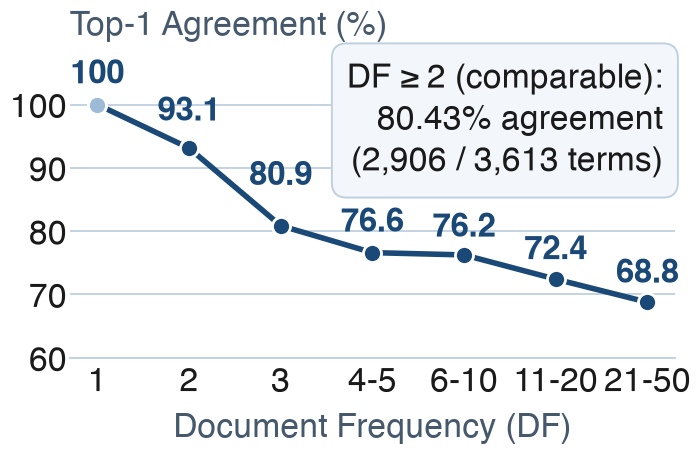

Output path        : /Users/yougeshdhomeja/Documents/NLP_Poster_Presentation/images/top1_agreement_by_df.png
Pixel width        : 4191 px
Pixel height       : 2724 px
Intrinsic width    : 6.99 in (17.74 cm)
Intrinsic height   : 4.54 in (11.53 cm)
Aspect (h / w)     : 0.650 (the bar chart it replaces was 0.985, nearly square)
File size          : 516,016 bytes
Format             : PNG
DPI (metadata)     : 600 x 600
Ink margin         : 60 px on the tightest edge (0 px would mean clipping)
Canvas             : 709 x 470 px at 100 dpi, no text past the edge
Band label gaps    : 5.9 px at the tightest pair (positive means no overlap)
Percentage gaps    : 28.7 px at the tightest pair (positive means no overlap)
Effective at 18 cm  : axis 24.3 pt, percentages 24.3 pt, summary card 24.3 pt
Y axis             : 60 to 109, ticks [60, 70, 80, 90, 100] (clipped baseline, agreement variation)
Bands shown        : 1 (100.00%), 2 (93.12%), 3 (80.86%), 4-5 (76.60%), 6-10 (76.24%), 11-20 (72.41%), 21-

In [7]:
# ---------------------------------------------------------------------------
# Section 4 figure: top-1 agreement by DF band (line chart)
# ---------------------------------------------------------------------------
# Every plotted value, label and count is read from the Section 4 tables
# above; none of them is typed in here. Each plotted percentage is agreement
# over the comparable queries in that band - the queries where BOTH rankers
# return a top-1 - so the DF = 21-50 band is 207 / 301, with the 8 terms whose
# TF-IDF IDF is 0 excluded. The x axis is the ordered sequence of DF bands, so
# the line itself shows how top-1 agreement falls away as a term appears in
# more documents.
import os

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

IMAGE_DIR = PROJECT_ROOT / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_PATH = IMAGE_DIR / "top1_agreement_by_df.png"

POSTER_BLUE = (26 / 255, 73 / 255, 120 / 255)   # poster header blue
PALE_BLUE = "#9DBBD6"                           # the DF = 1 point: 100% by construction
GRID_COLOUR = "#BFD0E0"
TEXT_COLOUR = "#1A1A1A"
MUTED_COLOUR = "#46586B"
CARD_COLOUR = "#F3F7FB"

# The canvas is laid out at the width the figure is printed at (18 cm), so
# these font sizes are the sizes the poster reader sees in a narrow column.
FIGURE_WIDTH_IN = 18.0 / 2.54
FIGURE_HEIGHT_IN = 4.7
LAYOUT_DPI = 100
AXIS_FONT = 24.0                    # axis titles and tick labels
POINT_FONT = 24.0                   # the percentage beside each marker
CALLOUT_FONT = 24.0                 # the DF >= 2 summary card
Y_MIN, Y_MAX = 60.0, 109.0          # the axis shows the variation in agreement,
Y_TICKS = (60, 70, 80, 90, 100)     # not magnitude from zero
Y_TICK_PAD = 2
X_TICK_PAD = 6
X_PAD = 0.30
AXES_RECT = [0.087, 0.235, 0.854, 0.66]
MARKER_SIZE = 13.0
COLUMN_CM = 18.0

plt.rcParams["font.family"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["figure.facecolor"] = "white"

# ---------------------------------------------------------------------------
# Data for the chart, taken from the computed Section 4 rows
# ---------------------------------------------------------------------------
band_ranges = [label.replace("DF = ", "") for label in rq3_band_table["Selection"]]
band_percent = [float(value) for value in rq3_band_table["Agreement (%)"]]
rq3_df2_row = rq3_row(rq3_overall_table, "Terms with DF >= 2")

positions = list(range(len(band_percent)))
# One decimal, exactly as the band table rounds it. The unit is carried by the
# axis title and the summary card: seven "%" labels of this width would touch
# at the 24 pt this figure is designed for.
point_text = [
    "100" if percent == 100.0 else f"{percent:.1f}" for percent in band_percent
]

figure = plt.figure(
    figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN), dpi=LAYOUT_DPI, facecolor="white"
)
axes = figure.add_axes(AXES_RECT)
axes.set_xlim(-X_PAD, len(positions) - 1 + X_PAD)
axes.set_ylim(Y_MIN, Y_MAX)
axes.set_yticks(Y_TICKS)
axes.set_yticklabels(
    [str(value) for value in Y_TICKS], fontsize=AXIS_FONT, color=TEXT_COLOUR
)
axes.set_xticks(positions)
axes.set_xticklabels(band_ranges, fontsize=AXIS_FONT, color=TEXT_COLOUR)
axes.tick_params(axis="y", length=0, pad=Y_TICK_PAD)
axes.tick_params(axis="x", length=0, pad=X_TICK_PAD)
axes.grid(axis="y", color=GRID_COLOUR, linewidth=1.3, zorder=0)
axes.set_axisbelow(True)
for side in ("top", "right", "left"):
    axes.spines[side].set_visible(False)
axes.spines["bottom"].set_color(GRID_COLOUR)
axes.spines["bottom"].set_linewidth(1.3)

# The line, and the DF = 1 point picked out in pale blue because that band is
# 100% by construction (one candidate document), not by evidence.
axes.plot(
    positions, band_percent, color=POSTER_BLUE, linewidth=4.0, zorder=3,
    marker="o", markersize=MARKER_SIZE, markerfacecolor=POSTER_BLUE,
    markeredgecolor="white", markeredgewidth=2.0,
)
axes.plot(
    [positions[0]], [band_percent[0]], linestyle="none", marker="o",
    markersize=MARKER_SIZE, markerfacecolor=PALE_BLUE, markeredgecolor="white",
    markeredgewidth=2.0, zorder=4,
)

axes.set_xlabel(
    "Document Frequency (DF)", fontsize=AXIS_FONT, color=MUTED_COLOUR, labelpad=11
)
figure.text(
    AXES_RECT[0], 0.975, "Top-1 Agreement (%)", fontsize=AXIS_FONT,
    color=MUTED_COLOUR, ha="left", va="top",
)

# The card states the DF >= 2 rate over its comparable queries, and the two
# counts behind it. "comparable" rides on the first line rather than the third
# because the card is width-limited by the DF = 1..3 labels it would otherwise
# cover: the line "(2,906 / 3,613 comparable queries)" measures 525 px against
# a 316 px card that clears them, and a wider card pushes the "100" label past
# the top of the y range.
callout = (
    f"DF ≥ 2 (comparable):\n{rq3_df2_row['Agreement (%)']:.2f}% agreement\n"
    f"({rq3_df2_row['Same top-1']:,} / "
    f"{rq3_df2_row['Comparable queries']:,} terms)"
)
callout_text = axes.text(
    0.98, 0.965, callout, transform=axes.transAxes, ha="right", va="top",
    fontsize=CALLOUT_FONT, color=TEXT_COLOUR, linespacing=1.35, zorder=6,
    bbox=dict(boxstyle="round,pad=0.45", facecolor=CARD_COLOUR,
              edgecolor=GRID_COLOUR, linewidth=1.4),
)

# ---------------------------------------------------------------------------
# Percentage labels: each sits directly above its own marker, at the smallest
# offset that still clears the marker, the line and every other piece of text
# (the two lowest bands differ by 0.36 points, so their labels are staggered).
# ---------------------------------------------------------------------------
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
to_pixels = axes.transData.transform
pixels_per_unit = abs(to_pixels((0, 1))[1] - to_pixels((0, 0))[1])

probe = axes.text(0, 0, "93.1", fontsize=POINT_FONT, fontweight="bold")
figure.canvas.draw()
probe_box = probe.get_window_extent(renderer=renderer)
probe.remove()
LABEL_WIDTH, LABEL_HEIGHT = probe_box.width, probe_box.height
MARKER_CLEARANCE = 2.0 * pixels_per_unit      # clear the marker circle itself
CLEARANCE = 5.0                               # px of daylight around a label

line_pixels = []
for index in range(len(positions) - 1):
    for step in range(81):
        fraction = step / 80.0
        line_pixels.append(
            to_pixels(
                (
                    positions[index] + fraction * (positions[index + 1] - positions[index]),
                    band_percent[index]
                    + fraction * (band_percent[index + 1] - band_percent[index]),
                )
            )
        )


def text_inventory():
    """Every text object this figure draws, listed once each."""
    return [
        text
        for text in (
            *axes.get_xticklabels(),
            *axes.get_yticklabels(),
            axes.xaxis.label,
            *figure.texts,
            *axes.texts,
        )
        if text.get_text().strip()
    ]


# The summary card draws a padded box around its text, so its padding is
# reserved as well.
CARD_PADDING = 0.45 * CALLOUT_FONT * LAYOUT_DPI / 72.0
existing_boxes = []
for text in text_inventory():
    text_box = text.get_window_extent(renderer=renderer)
    padding = CARD_PADDING if text is callout_text else 0.0
    existing_boxes.append(
        (
            text_box.x0 - padding,
            text_box.y0 - padding,
            text_box.x1 + padding,
            text_box.y1 + padding,
        )
    )

top_limit = to_pixels((0, Y_MAX))[1]
label_offsets = []
placed_boxes = []
for position, percent in zip(positions, band_percent):
    centre_x, centre_y = to_pixels((position, percent))
    required = centre_y + MARKER_CLEARANCE
    for line_x, line_y in line_pixels:            # clear the line under the label
        if (
            centre_x - LABEL_WIDTH / 2 - CLEARANCE
            <= line_x
            <= centre_x + LABEL_WIDTH / 2 + CLEARANCE
        ):
            required = max(required, line_y + CLEARANCE)
    offset = (required - centre_y) / pixels_per_unit
    while True:                                   # and clear every text box
        box = (
            centre_x - LABEL_WIDTH / 2,
            centre_y + offset * pixels_per_unit,
            centre_x + LABEL_WIDTH / 2,
            centre_y + offset * pixels_per_unit + LABEL_HEIGHT,
        )
        blocked = [
            other
            for other in existing_boxes + placed_boxes
            if not (
                box[2] + 3 <= other[0]
                or other[2] + 3 <= box[0]
                or box[3] + 3 <= other[1]
                or other[3] + 3 <= box[1]
            )
        ]
        if not blocked:
            break
        offset = (max(other[3] for other in blocked) + 3 - centre_y) / pixels_per_unit
    assert centre_y + offset * pixels_per_unit + LABEL_HEIGHT <= top_limit, \
        "a percentage label would not fit inside the y range"
    placed_boxes.append(box)
    label_offsets.append(offset)

point_labels = [
    axes.text(
        position, percent + offset, text, ha="center", va="bottom",
        fontsize=POINT_FONT, fontweight="bold", color=POSTER_BLUE, zorder=6,
    )
    for position, percent, offset, text in zip(
        positions, band_percent, label_offsets, point_text
    )
]

# ---------------------------------------------------------------------------
# Layout checks, done before the export
# ---------------------------------------------------------------------------
# The canvas is the printed width, so no text may reach past it: bbox_inches
# ="tight" would widen the file and shrink every font on the poster.
figure.canvas.draw()
canvas_width = figure.bbox.width
canvas_height = figure.bbox.height
drawn_texts = text_inventory()
drawn_boxes = [
    text.get_window_extent(renderer=renderer) for text in drawn_texts
]
outside = [
    text.get_text()
    for text, box in zip(drawn_texts, drawn_boxes)
    if box.x1 > canvas_width + 0.5
    or box.x0 < -0.5
    or box.y1 > canvas_height + 0.5
    or box.y0 < -0.5
]
assert not outside, f"text runs past the {COLUMN_CM:.0f} cm canvas: {outside}"

overlaps = [
    (drawn_texts[first].get_text(), drawn_texts[second].get_text())
    for first in range(len(drawn_texts))
    for second in range(first + 1, len(drawn_texts))
    if not (
        drawn_boxes[first].x1 <= drawn_boxes[second].x0
        or drawn_boxes[second].x1 <= drawn_boxes[first].x0
        or drawn_boxes[first].y1 <= drawn_boxes[second].y0
        or drawn_boxes[second].y1 <= drawn_boxes[first].y0
    )
]
assert not overlaps, f"text overlaps: {overlaps}"

band_boxes = [text.get_window_extent(renderer=renderer)
              for text in axes.get_xticklabels()]
band_gaps = [
    band_boxes[index + 1].x0 - band_boxes[index].x1
    for index in range(len(band_boxes) - 1)
]
assert min(band_gaps) > 0, "the DF band labels overlap"

point_boxes = [text.get_window_extent(renderer=renderer) for text in point_labels]
point_gaps = [
    point_boxes[index + 1].x0 - point_boxes[index].x1
    for index in range(len(point_boxes) - 1)
]
assert min(point_gaps) > 0, "the percentage labels overlap"

# The values the line actually plots are the computed band percentages.
plotted = [float(value) for value in axes.lines[0].get_ydata()]
assert plotted == band_percent, "a plotted value differs from the band table"

figure.savefig(FIGURE_PATH, dpi=600, bbox_inches="tight", facecolor="white")
plt.show()

# ---------------------------------------------------------------------------
# Saved image properties, and a check that nothing is clipped
# ---------------------------------------------------------------------------
with Image.open(FIGURE_PATH) as saved_image:
    pixel_width, pixel_height = saved_image.size
    saved_format = saved_image.format
    saved_dpi = saved_image.info.get("dpi")
    ink = (np.asarray(saved_image.convert("RGB")) < 250).any(axis=2)

file_size = os.path.getsize(FIGURE_PATH)
ink_rows = np.where(ink.any(axis=1))[0]
ink_cols = np.where(ink.any(axis=0))[0]
assert len(ink_rows) and len(ink_cols), "the figure rendered nothing"
ink_margin = min(
    ink_rows[0],
    ink_cols[0],
    pixel_height - 1 - ink_rows[-1],
    pixel_width - 1 - ink_cols[-1],
)
assert ink_margin > 0, "figure content touches the image edge (clipping)"

saved_dpi_value = saved_dpi[0] if saved_dpi else 600.0
figure_width_in = pixel_width / saved_dpi_value
figure_height_in = pixel_height / saved_dpi_value
scale_at_column = (COLUMN_CM / 2.54) / figure_width_in
assert AXIS_FONT * scale_at_column >= 24.0, "axis text under 24 pt at 18 cm"
assert POINT_FONT * scale_at_column >= 24.0, "percentage labels under 24 pt at 18 cm"
assert CALLOUT_FONT * scale_at_column >= 24.0, "summary card under 24 pt at 18 cm"

print(f"Output path        : {FIGURE_PATH}")
print(f"Pixel width        : {pixel_width} px")
print(f"Pixel height       : {pixel_height} px")
print(f"Intrinsic width    : {figure_width_in:.2f} in "
      f"({figure_width_in * 2.54:.2f} cm)")
print(f"Intrinsic height   : {figure_height_in:.2f} in "
      f"({figure_height_in * 2.54:.2f} cm)")
print(f"Aspect (h / w)     : {figure_height_in / figure_width_in:.3f} "
      f"(the bar chart it replaces was 0.985, nearly square)")
print(f"File size          : {file_size:,} bytes")
print(f"Format             : {saved_format}")
if saved_dpi:
    print(f"DPI (metadata)     : {saved_dpi[0]:.0f} x {saved_dpi[1]:.0f}")
print(f"Ink margin         : {ink_margin} px on the tightest edge "
      f"(0 px would mean clipping)")
print(f"Canvas             : {canvas_width:.0f} x {canvas_height:.0f} px at "
      f"{LAYOUT_DPI} dpi, no text past the edge")
print(f"Band label gaps    : {min(band_gaps):.1f} px at the tightest pair "
      f"(positive means no overlap)")
print(f"Percentage gaps    : {min(point_gaps):.1f} px at the tightest pair "
      f"(positive means no overlap)")
print(f"Effective at {COLUMN_CM:.0f} cm  : axis {AXIS_FONT * scale_at_column:.1f} pt, "
      f"percentages {POINT_FONT * scale_at_column:.1f} pt, "
      f"summary card {CALLOUT_FONT * scale_at_column:.1f} pt")
print(f"Y axis             : {Y_MIN:.0f} to {Y_MAX:.0f}, ticks {list(Y_TICKS)} "
      f"(clipped baseline, agreement variation)")
print("Bands shown        : "
      + ", ".join(f"{label} ({percent:.2f}%)"
                  for label, percent in zip(band_ranges, band_percent)))
print("Plotted points     : "
      + ", ".join(f"{label} {text}" for label, text in zip(band_ranges, point_text)))
print(f"Summary card       : {callout.splitlines()!r}")
print(f"DF = 1 marker      : pale {PALE_BLUE}, remaining markers "
      f"RGB{tuple(round(255 * channel) for channel in POSTER_BLUE)}")

# ---------------------------------------------------------------------------
# Rendered text size if the figure is placed with width=\linewidth
# (the figure is scaled by column_width / figure_width).
# ---------------------------------------------------------------------------
for label, column_cm in (("18 cm", COLUMN_CM), ("20 cm", 20.0), ("24 cm", 24.0)):
    column_in = column_cm / 2.54
    print(f"At {label:>6s} column: axis {AXIS_FONT * column_in / figure_width_in:5.1f} pt, "
          f"percentages {POINT_FONT * column_in / figure_width_in:5.1f} pt, "
          f"summary card {CALLOUT_FONT * column_in / figure_width_in:5.1f} pt "
          f"(height {figure_height_in * column_in / figure_width_in:.2f} in)")


Agreement is measured only across comparable queries: those where both rankers return a top-ranked document. Eight of the 6,206 terms (`but`, `he`, `i`, `me`, `not`, `s`, `that`, `with`) occur in all 50 documents, so their TF-IDF IDF is ln(50/50) = 0 and `rank_tfidf` returns no ranking for them; a query with only one ranking has no agreement outcome at all, since it is neither the same document nor a different one, so those terms are excluded from the denominator instead of being counted as a disagreement. BM25 returns a ranking for all 6,206 terms.

That leaves 6,198 comparable queries, of which 5,491 agree (88.59%), and 3,613 comparable queries with DF >= 2, of which 2,906 agree (80.43%). Every one of the 2,585 terms with DF = 1 agrees, but only because a single posting leaves both rankers a single candidate: that band is 100% by construction, not by evidence, which is why the DF >= 2 rate is the informative one. Above DF = 2 the rate falls band by band, from 93.12% at DF = 2 to 68.77% at DF = 21-50, so agreement is lowest exactly where a term occurs in many documents and document-length normalisation has the most room to reorder the list. Every figure here is a measurement on this 50-document corpus with this preprocessing pipeline: it describes how the two implementations behave on this collection, not a general law about TF-IDF and BM25.
